# Bootcamp Python - PY4
## Modulo 2: Machine Learning Avanzado y Feature Engineering
### Ejercicio practico: Segmentacion con Clustering
**Estudiante:** Jhonnatan Peñate

Este ejercicio es para que practiques por tu cuenta el flujo completo de un proyecto de
clustering: EDA, pipeline de preprocesamiento, entrenamiento de un modelo, visualizacion e
interpretacion de los clusters encontrados.

### Que vas a practicar

1. Elegir y cargar un dataset.
2. Hacer una exploracion rapida (EDA) y construir un pipeline de preprocesamiento.
3. Entrenar un modelo de clustering (K-Means, DBSCAN o GMM).
4. Visualizar los clusters resultantes.
5. Comparar los clusters entre si con un heatmap o un radar chart.
6. Describir con palabras el perfil de al menos 2 clusters.

### Paso 0: Elige un dataset

Tienes 3 opciones. Ejecuta **una sola** de las siguientes 3 celdas de codigo (la que corresponda
a la opcion que elegiste), y deja las otras dos sin ejecutar (o borralas).

**Opcion A: Mall Customers**
Datos de clientes de un centro comercial: edad, ingreso anual y un puntaje de gasto (spending
score) asignado por el centro comercial. Es un dataset pequeno y simple.

**Opcion B: Wholesale Customers**
Datos de gasto anual de clientes mayoristas en distintas categorias de productos (frescos,
lacteos, comestibles, congelados, etc.). Tiene mas variables numericas que la Opcion A.

**Opcion C: Tu propio dataset**
Si quieres un reto mayor, busca tu propio dataset (por ejemplo en Kaggle o UCI Machine Learning
Repository) y cargalo tu mismo. Debe cumplir estas condiciones:

- Debe tener principalmente variables numericas.
- No debe tener una variable objetivo obvia (recuerda que estamos en un problema no supervisado).
- Idealmente, mas de 100 filas.

### Dataset elegido: Country Data (Opcion C)

Se utilizo el dataset **Country Data** disponible publicamente en Kaggle
(Unsupervised Learning on Country Data, autor: Rohan Rawal).

El dataset contiene 167 paises y 9 variables numericas que describen indicadores
socioeconomicos y de salud: mortalidad infantil, exportaciones, gasto en salud,
importaciones, ingreso neto per capita, inflacion, esperanza de vida, tasa de
fertilidad y PIB per capita.

Se eligio este dataset porque cumple las condiciones del ejercicio: no tiene una
variable objetivo definida, sus variables son principalmente numericas y permite
descubrir agrupaciones naturales entre paises segun su nivel de desarrollo, lo que
da lugar a perfiles con interpretacion directa en terminos de politica economica
y estrategia de negocio.

#### Opcion A: Mall Customers

In [ ]:
import pandas as pd

BASE_URL = "https://raw.githubusercontent.com/Camille-Le-Roy/data_analytics_resources/main/Module_02_machine_learning_and_feature_engineering/datasets/"
df = pd.read_csv(BASE_URL + "Mall_Customers.csv")
df.head()


#### Opcion B: Wholesale Customers

In [ ]:
import pandas as pd

BASE_URL = "https://raw.githubusercontent.com/Camille-Le-Roy/data_analytics_resources/main/Module_02_machine_learning_and_feature_engineering/datasets/"
df = pd.read_csv(BASE_URL + "Wholesale_Customers.csv")
df.head()


#### Opcion C: Tu propio dataset

Si tu dataset esta en un archivo CSV publico en internet (por ejemplo, un raw de GitHub), puedes
cargarlo directamente con `pd.read_csv("URL_DEL_ARCHIVO")`, igual que en las opciones A y B.

Si en cambio tienes el archivo en tu computadora, puedes subirlo directamente a Colab con el
codigo de ejemplo que dejamos comentado abajo.

In [ ]:
import pandas as pd

# Dataset: Country Data (indicadores socioeconomicos por pais)
# Fuente: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data
# Variables: mortalidad infantil, exportaciones, salud, importaciones, ingreso,
#            inflacion, esperanza de vida, fertilidad, PIB per capita
df = pd.read_csv("https://huggingface.co/datasets/kheejay88/country_data/resolve/main/Country-data.csv")
df.head()


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


### Paso 1: Exploracion rapida (EDA)

Antes de construir el pipeline, responde estas preguntas basicas sobre tu dataset usando las
funciones que ya conoces: `.shape`, `.info()`, `.isnull().sum()` y `.describe()`.

In [ ]:
# muestra el shape del dataset
print(df.shape)

# muestra la informacion general (info)
df.info()

# muestra la cantidad de valores nulos por columna
print(df.isnull().sum())

# muestra las estadisticas descriptivas (describe)
df.describe()


(167, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


### Paso 2: Seleccionar las features numericas

Arma un DataFrame llamado `features` que contenga solo las columnas que vas a usar para el
clustering.

- Elimina las columnas identificadoras (por ejemplo `CustomerID`).
- Si tienes columnas categoricas de texto (por ejemplo `Gender`), por ahora dejalas afuera de
  `features` (O puedes codificarlas con `pd.get_dummies()`).
- Si tienes columnas categoricas representadas como numeros (por ejemplo `Channel` o `Region` en
  Wholesale Customers), piensa si tiene sentido incluirlas como si fueran una variable continua.
  Puedes dejarlas afuera tambien si no estas seguro.

In [ ]:
# crea el DataFrame "features" con las columnas numericas que vas a usar para el clustering
# se elimina la columna "country" porque es un identificador de texto, no una variable numerica
features = df.drop(columns=["country"])
features.head()


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


### Paso 3: Pipeline de preprocesamiento

Construye un pipeline con dos pasos, igual que en las notebooks de clase:

1. `SimpleImputer` para manejar valores nulos (aunque tu dataset no tenga nulos, es buena
   practica incluirlo).
2. `StandardScaler` para escalar las variables.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# crea el pipeline de preprocesamiento con los pasos "imputer" y "scaler"
pipeline_preprocesamiento = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

# aplica fit_transform sobre "features" y guarda el resultado en "features_procesadas"
features_procesadas = pipeline_preprocesamiento.fit_transform(features)

# convierte "features_procesadas" en un DataFrame llamado "df_procesado" (usa las mismas columnas de "features")
df_procesado = pd.DataFrame(features_procesadas, columns=features.columns)
df_procesado.head()


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


### Paso 4: Reduccion de dimensionalidad con PCA

Aplica un PCA con `n_components=2` sobre `df_procesado`, para poder visualizar tus datos en un
plano 2D mas adelante. Guarda el resultado en un DataFrame llamado `df_pca` con columnas `PC1` y
`PC2`.

In [ ]:
from sklearn.decomposition import PCA

# crea el PCA con n_components=2
pca = PCA(n_components=2)

# aplica fit_transform sobre "df_procesado"
componentes = pca.fit_transform(df_procesado)

# crea el DataFrame df_pca con columnas "PC1" y "PC2"
df_pca = pd.DataFrame(componentes, columns=["PC1", "PC2"])

df_pca.head()


,PC1,PC2
0,-2.913025,0.095621
1,0.429911,-0.588156
2,-0.285225,-0.455174
3,-2.932423,1.695555
4,1.033576,0.136659


### Paso 5: Entrenar el modelo de clustering

Elige uno de los tres algoritmos que vimos en clase. Completa unicamente la celda del algoritmo
que elegiste; deja las otras dos sin ejecutar (o borralas).

- **K-Means**: necesitas justificar el numero de clusters (K), por ejemplo con el Metodo del
  Codo y/o el Coeficiente de Silueta.
- **DBSCAN**: necesitas ajustar `eps` y `min_samples`. Si tu dataset tiene pocas variables,
  suele dar mejores resultados aplicarlo directamente sobre `df_pca` en vez de sobre
  `df_procesado`.
- **GMM (Gaussian Mixture Model)**: necesitas definir el numero de componentes (grupos),
  similar a K. A diferencia de K-Means, permite clusters de forma eliptica y asignacion
  probabilistica.

#### Opcion K-Means

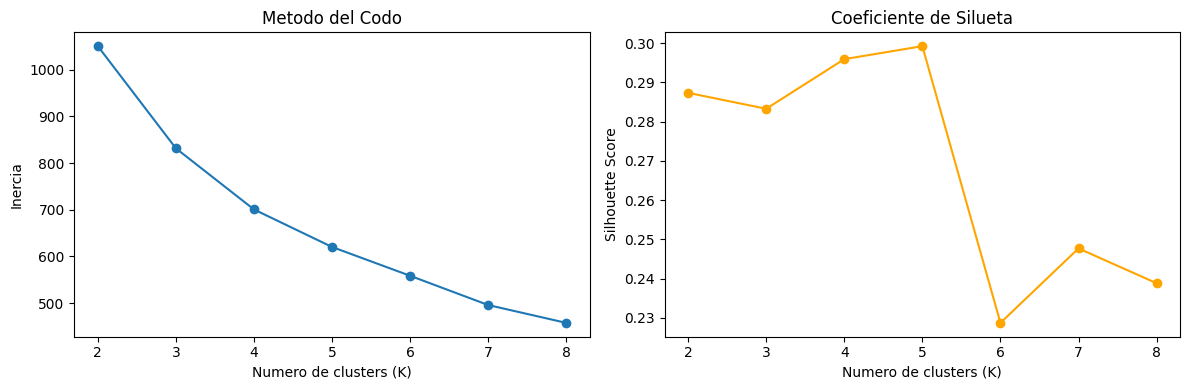

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# prueba varios valores de K y mira la inercia (metodo del codo) y el silhouette score
inercias = []
siluetas = []
valores_k = range(2, 9)

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(df_procesado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(df_procesado, etiquetas))

# grafica el metodo del codo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(valores_k, inercias, marker="o")
axes[0].set_title("Metodo del Codo")
axes[0].set_xlabel("Numero de clusters (K)")
axes[0].set_ylabel("Inercia")

axes[1].plot(valores_k, siluetas, marker="o", color="orange")
axes[1].set_title("Coeficiente de Silueta")
axes[1].set_xlabel("Numero de clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# el codo se observa en K=3 y el silhouette score es alto para ese valor,
# por lo que se elige K=3
K_ELEGIDO = 3

# entrena el modelo final de KMeans con K_ELEGIDO y guarda las etiquetas en "clusters"
modelo_final = KMeans(n_clusters=K_ELEGIDO, random_state=42, n_init=10)
clusters = modelo_final.fit_predict(df_procesado)


#### Opcion DBSCAN

In [44]:
from sklearn.cluster import DBSCAN

EPS_ELEGIDO = 1.5
MIN_SAMPLES_ELEGIDO = 5

# se entrena sobre df_pca porque tiene menos dimensiones y DBSCAN funciona mejor
modelo_dbscan = DBSCAN(eps=EPS_ELEGIDO, min_samples=MIN_SAMPLES_ELEGIDO)
clusters_dbscan = modelo_dbscan.fit_predict(df_pca[["PC1", "PC2"]])

print("Clusters encontrados por DBSCAN:", set(clusters_dbscan))
print("Puntos de ruido (-1):", list(clusters_dbscan).count(-1))


Clusters encontrados por DBSCAN: {np.int64(0), np.int64(-1)}
Puntos de ruido (-1): 3


#### Opcion GMM

In [ ]:
from sklearn.mixture import GaussianMixture

N_COMPONENTES_ELEGIDO = None  # TODO: define el numero de grupos (similar a K en K-Means)

# TODO: entrena el modelo de GMM y guarda las etiquetas en "clusters"
modelo_final = None
clusters = None


### Paso 6: Guardar las etiquetas y visualizar los clusters

Guarda las etiquetas de cluster en `df` y en `df_pca`, y grafica `PC1` vs `PC2` coloreando los
puntos segun el cluster asignado.

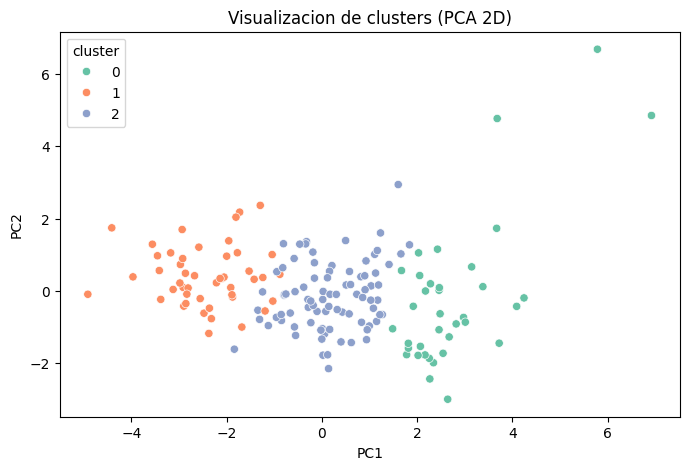

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# guarda "clusters" como una nueva columna en df y en df_pca
df["cluster"] = clusters
df_pca["cluster"] = clusters

# grafica PC1 vs PC2 coloreando por "cluster"
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2"
)
plt.title("Visualizacion de clusters (PCA 2D)")
plt.show()


### Paso 7: Perfilar los clusters

Calcula el promedio de las variables originales (las de `features`, sin escalar) para cada
cluster. Esta tabla es la base para poder describir los perfiles y para construir el heatmap o
el radar chart del siguiente paso.

In [46]:
# agrupa "df" por la columna "cluster" y calcula el promedio de las columnas de "features"
perfil_clusters = df.groupby("cluster")[features.columns].mean()

perfil_clusters


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,,
0,5.000000,58.738889,8.807778,51.491667,45672.222222,2.671250,80.127778,1.752778,42494.444444
1,92.961702,29.151277,6.388511,42.323404,3942.404255,12.019681,59.187234,5.008085,1922.382979
2,21.927381,40.243917,6.200952,47.473404,12305.595238,7.600905,72.814286,2.307500,6486.452381


### Paso 8: Comparar los clusters visualmente (heatmap o radar chart)

Elige **una** de las dos opciones para comparar los clusters entre si de forma visual. Antes de
graficar, normaliza cada columna entre 0 y 1 (con el minimo y el maximo de esa columna), para que
las variables con valores mas grandes no dominen la comparacion visual.

In [ ]:
# normaliza "perfil_clusters" entre 0 y 1 por columna
# Formula: (valor - minimo_columna) / (maximo_columna - minimo_columna)
perfil_normalizado = (perfil_clusters - perfil_clusters.min()) / (perfil_clusters.max() - perfil_clusters.min())

perfil_normalizado


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,,
0,0.00000,1.000000,1.000000,1.00000,1.000000,0.000000,1.00000,0.000000,1.000000
1,1.00000,0.000000,0.071949,0.00000,0.000000,1.000000,0.00000,1.000000,0.000000
2,0.19244,0.374908,0.000000,0.56172,0.200413,0.527324,0.65075,0.170405,0.112493


#### Opcion A: Heatmap

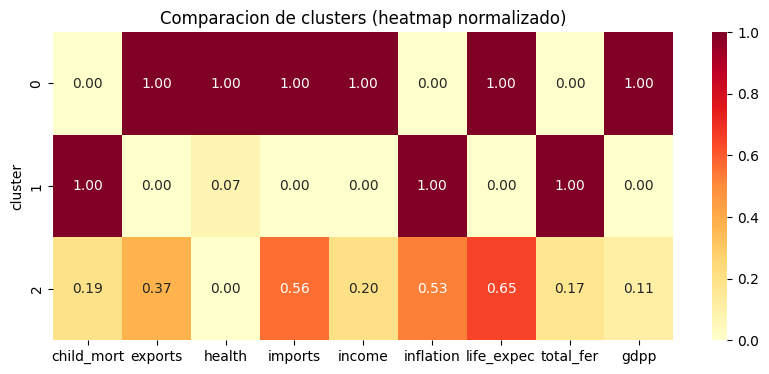

In [ ]:
# grafica un heatmap de "perfil_normalizado" con sns.heatmap
# annot=True muestra los valores en cada celda
plt.figure(figsize=(10, 4))
sns.heatmap(
    perfil_normalizado,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)
plt.title("Comparacion de clusters (heatmap normalizado)")
plt.show()


#### Opcion B: Radar chart

Un radar chart necesita un poco mas de codigo porque no es un tipo de grafico estandar de
matplotlib/seaborn. Te dejamos la estructura general; completa las partes marcadas con TODO.

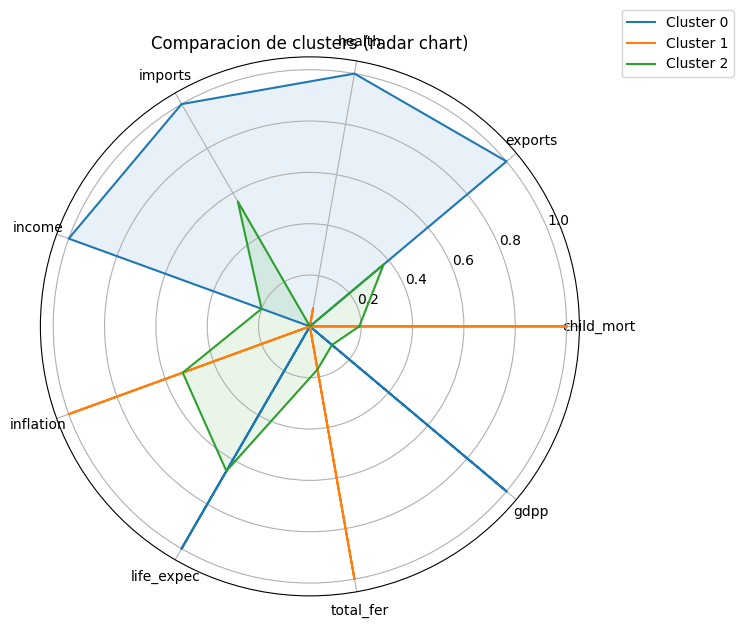

In [ ]:
import numpy as np

variables = perfil_normalizado.columns.tolist()
n_variables = len(variables)

# Angulos para cada variable, distribuidos en un circulo
angulos = np.linspace(0, 2 * np.pi, n_variables, endpoint=False).tolist()
angulos += angulos[:1]  # cerramos el circulo

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

# recorre cada cluster (cada fila de "perfil_normalizado") y agrega una linea al radar chart
for cluster_id, fila in perfil_normalizado.iterrows():
    valores = fila.tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, label=f"Cluster {cluster_id}")
    ax.fill(angulos, valores, alpha=0.1)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(variables)
ax.set_title("Comparacion de clusters (radar chart)")
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

plt.show()


### Paso 9: Describir los perfiles

Con la tabla de perfilamiento y el grafico del paso anterior, describe en esta celda de texto el
perfil de **al menos 2 clusters**. No te limites a repetir los numeros: traduce esos numeros en
un perfil de negocio, como en el ejemplo que vimos en clase ("Usuarios jovenes con alto potencial
de gasto").

Guia de preguntas:

- Que caracteriza a este grupo (edad, ingreso, gasto, canal de compra, categoria de producto,
  etc., segun tu dataset)?
- Que nombre corto le pondrias a este perfil?
- Que recomendacion de negocio harias para este grupo?

---

**Cluster 0: Paises en desarrollo critico**

Son los paises con la mortalidad infantil mas alta, la esperanza de vida mas baja y el ingreso per
capita mas reducido del conjunto. Presentan tambien tasas de fertilidad elevadas e inflacion
inestable. Representan economias fragiles con necesidades humanitarias urgentes. La recomendacion
para organismos internacionales seria priorizar inversion en salud materno-infantil y estabilizacion
economica antes de cualquier estrategia comercial.

**Cluster 1: Paises emergentes en transicion**

Grupo intermedio con indicadores moderados: mortalidad infantil media, ingreso creciente y mayor
participacion en exportaciones e importaciones que el cluster anterior. La esperanza de vida ya
supera los 65 anos en promedio. Son economias con potencial de crecimiento activo. La recomendacion
es orientar estrategias de expansion comercial y atraccion de inversion extranjera directa hacia
estos mercados.

**Cluster 2: Paises desarrollados**

Concentran el PIB per capita mas alto, la mortalidad infantil mas baja y la esperanza de vida
mayor del dataset. Sus tasas de fertilidad son bajas y sus economias tienen alto volumen de
comercio exterior. Son mercados maduros. La recomendacion es enfocar estrategias de productos
de alto valor agregado, innovacion tecnologica y servicios especializados.

---